# Jensen Huang reinstated as NVIDIA CEO: who clicked first?

**Event:** NVIDIA's GlobeNewswire release, stamped *8:55 AM ET, 2026-11-23* (to the minute only).
**Question:** when did takers start buying YES on "Jensen returns", which venue moved first, and was Hyperliquid's NVDA perp the trigger?

The written finding is [`reports/2026-11-23-jensen.md`](../reports/2026-11-23-jensen.md); this notebook is the evidence behind it. Event window, markets and thresholds live in [`events/2026-11-23-jensen.toml`](../events/2026-11-23-jensen.toml); the raw pulls and their provenance are in `data/raw/2026-11-23-jensen/` (see `manifest.json`). Times are ET (UTC−5).

| Venue | What's public | Timestamp | Taker identity |
|---|---|---|---|
| Hyperliquid `xyz:NVDA` | every fill (Ironflow; S3 archive) | block time, ms | wallet |
| Kalshi | full trade tape (older trades via `/historical/trades`) | matching engine, µs | none |
| Polymarket (polymarket.com) | every taker fill (on-chain) | Polygon block, 1 s, ~1–3 s after the match | proxy wallet |
| Polymarket US | **no trade history**; ~1-minute book-derived display prices | minute | none |

In [1]:
%matplotlib inline
import pandas as pd
from newsflow import analysis, pipeline
from newsflow.event import load

pd.set_option("display.max_rows", 200, "display.width", 200, "display.float_format", "{:,.4g}".format)
ev = load(pipeline.ROOT / "events" / "2026-11-23-jensen.toml")
tape = pipeline.tape(ev)
pmus = pipeline.pmus_prices(ev)
buys = tape[tape.side > 0]
tape.groupby(["venue", "label"]).agg(fills=("qty", "size"), first=("clock", "min"), last=("clock", "max")).join(
    buys.groupby(["venue", "label"]).agg(yes_buy_qty=("qty", "sum"), yes_buy_usd=("usd", "sum")))

fills         first          last  yes_buy_qty  yes_buy_usd
venue       label                                                                                     
hyperliquid HL xyz:NVDA                    11535  08:54:00.023  08:57:59.966    4.851e+05    7.113e+07
kalshi      K CEO hire = Jensen returns       23  08:55:57.906  08:57:59.393    1.084e+04        1,856
            K next CEO = Jensen             1228  08:54:12.566  08:57:58.451    2.072e+06    8.557e+05
            K next employer = Nvidia         318  08:55:47.179  08:57:55.774     1.18e+05    3.147e+04
polymarket  PM rejoin by december-31-2026    134  08:54:50.000  08:57:59.000    2.291e+05    1.163e+05
            PM rejoin by december-31-2027    111  08:55:53.000  08:57:44.000    5.563e+04     3.11e+04
            PM rejoin by march-31-2027        63  08:55:53.000  08:57:23.000    1.457e+04        7,460
            PM rejoin by november-30-2026    185  08:54:14.000  08:57:53.000    2.268e+05    1.271e+05

## 1. First taker bursts per market
A *burst* is a bucket where YES/long taker buying reaches a venue-specific size (`[bursts]` in the event config): HL $100k per 0.5 s, Kalshi $5k per 0.5 s, Polymarket $2k per 1 s (block time is whole seconds, and the nearest-dated Polymarket markets were 3–12¢).

In [2]:
b = analysis.bursts_by_market(tape, ev.bursts)
for label, t in b.groupby("label", sort=False):
    print(f"\n== {label}")
    print(t.head(8)[["clock", "qty", "usd", "px_lo", "px_hi", "top_taker", "top_share"]].to_string(index=False))


== HL xyz:NVDA
       clock   qty       usd  px_lo  px_hi  top_taker  top_share
08:55:41.068 1,759 2.392e+05  135.9    136 0x25773676     0.9985
08:55:41.622 4,582 6.235e+05    136  136.1 0x0de52cf0     0.5612
08:55:42.022 3,186 4.336e+05  136.1  136.1 0x5234a0bb     0.6278
08:55:42.509 2,993 4.074e+05  136.1  136.2 0x0de52cf0     0.6573
08:55:43.027 3,272 4.456e+05  136.1  136.3 0x0de52cf0     0.5811
08:55:43.519 1,638 2.236e+05  136.3  136.6 0x0de52cf0     0.5517
08:55:44.047 1,354 1.851e+05  136.5  136.8 0x0de52cf0     0.6403
08:55:44.514 4,227 5.788e+05  136.8  137.2 0x21ba61c0     0.4631

== K next CEO = Jensen
       clock       qty       usd  px_lo  px_hi   top_taker  top_share
08:55:48.399 2.802e+05 4.809e+04   0.17   0.18 (anonymous)          1
08:55:57.906 9.105e+04 1.637e+04   0.17   0.18 (anonymous)          1
08:56:03.200   2.5e+05  4.78e+04   0.18   0.21 (anonymous)          1
08:56:05.510 3.994e+05 1.008e+05    0.2   0.33 (anonymous)          1
08:56:11.039 9.337e+04 3.

## 2. Timeline
Each market's first burst, with lags (seconds) against the first Hyperliquid burst and the reference timestamps.

In [3]:
first = analysis.first_bursts(b, ev.marks)
hl0 = first.query("venue == 'hyperliquid'").t_ms.min()
first.drop(columns=["t_ms", "top_share"])

,clock,qty,usd,px_lo,px_hi,top_taker,venue,label,vs_first_HL_s,vs_Press release minute_s,vs_First X posts_s
0,08:55:41.068,"1,759",2.392e+05,135.9,136,0x25773676,hyperliquid,HL xyz:NVDA,0,41.07,-10.43
1,08:55:48.399,2.802e+05,4.809e+04,0.17,0.18,(anonymous),kalshi,K next CEO = Jensen,7.331,48.4,-3.101
2,08:55:53.000,5.098e+04,"6,329",0.1241,0.1241,0x3e03eaee,polymarket,PM rejoin by december-31-2026,11.93,53,1.5
3,08:55:57.902,7.108e+04,"8,717",0.1,0.15,(anonymous),kalshi,K next employer = Nvidia,16.83,57.9,6.402
4,08:56:04.000,"6,153","2,457",0.398,0.42,0x853c37a9,polymarket,PM rejoin by december-31-2027,22.93,64,12.5
5,08:56:14.000,2.924e+04,1.461e+04,0.4996,0.4996,0x3e03eaee,polymarket,PM rejoin by november-30-2026,32.93,74,22.5
6,08:56:43.000,"2,608","2,304",0.8835,0.8835,0x73e35ce0,polymarket,PM rejoin by march-31-2027,61.93,103,51.5


- Hyperliquid moved first.
- Kalshi's first burst (the 280k-contract print in the PM Pulse chart) came 7.3 s later, while HL NVDA was already up.
- Polymarket's block times run ~1–3 s behind the match, so its true first fill is a little earlier than shown; it is still after Kalshi's.
- Polymarket US can't be placed on this timeline (section 6).

## 3. Kalshi vs Polymarket
YES taker dollars per second, 8:55:40–8:56:40, then what each market's early takers paid and made. Every market here resolved YES at $1.

In [4]:
W0 = hl0 - 1_000
w = buys[buys.venue.isin(["kalshi", "polymarket"]) & buys.t_ms.between(W0, W0 + 60_000)].copy()
w["group"] = w.label.where(w.venue == "kalshi", "PM rejoin (all markets)")
w["sec"] = w.time.dt.floor("s").dt.strftime("%H:%M:%S")
per_sec = w.pivot_table(index="sec", columns="group", values="usd", aggfunc="sum").fillna(0).round(0)
per_sec[per_sec.sum(axis=1) >= 1000]

group,K CEO hire = Jensen returns,K next CEO = Jensen,K next employer = Nvidia,PM rejoin (all markets)
sec,,,,
08:55:48,0,4.809e+04,0,0
08:55:53,0,14,165,"6,395"
08:55:54,0,"1,832",0,0
08:55:55,0,0,5,"5,430"
08:55:56,0,0,1,"7,002"
08:55:57,"1,757",1.637e+04,"8,717",0
08:55:58,0,"1,309",93,57
08:56:01,0,0,0,"4,531"
08:56:03,0,4.78e+04,0,0


In [5]:
pm_k = first[first.venue != "hyperliquid"]
pd.DataFrame({(r.label, f"first {s}s"): analysis.edge(buys[buys.label == r.label], r.t_ms, s)
              for r in pm_k.itertuples() for s in (15, 30, 60)}).T

risked_usd  contracts   vwap  profit_at_1_usd  fills
K next CEO = Jensen           first 15s   1.154e+05  6.394e+05 0.1805         5.24e+05    108
                              first 30s   5.779e+05  1.696e+06 0.3408        1.118e+06    604
                              first 60s   6.743e+05  1.833e+06 0.3678        1.159e+06    812
PM rejoin by december-31-2026 first 15s   2.062e+04  1.258e+05 0.1639        1.052e+05     23
                              first 30s   2.199e+04  1.286e+05 0.1709        1.066e+05     32
                              first 60s   2.617e+04  1.354e+05 0.1933        1.093e+05     65
K next employer = Nvidia      first 15s       9,234  7.373e+04 0.1253        6.449e+04     56
                              first 30s   1.186e+04  8.233e+04  0.144        7.047e+04    100
                              first 60s   1.971e+04  9.922e+04 0.1986        7.951e+04    180
PM rejoin by december-31-2027 first 15s   1.874e+04  3.987e+04 0.4701        2.113e+04     12
                              first 30s   1.951e+04  4.097e+04  0.476        2.147e+04     19
                              first 60s   2.494e+04  4.726e+04 0.5278        2.232e+04     52
PM rejoin by november-30-2026 first 15s   2.592e+04  5.186e+04 0.4998        2.594e+04     14
                              first 30s   2.914e+04  5.713e+04 0.5101        2.799e+04     27
                              first 60s   1.025e+05  1.336e+05 0.7671        3.112e+04     45
PM rejoin by march-31-2027    first 15s       2,314      2,619 0.8836            304.8      2
                              first 30s       2,643      2,969 0.8902            325.9      4
                              first 60s       4,009      4,401 0.9108            392.4      7

Kalshi printed far more size in the first 30 s than any Polymarket market. Kalshi's next-CEO market started at 17¢; Polymarket's nearest-dated markets started cheaper (Nov-30 about 3¢, Dec-31-2026 about 12¢), but their books were thin: Nov-30 went from about 3¢ (8:55:50) to 50¢ (8:56:14) in about 25 s, so only the first few wallets got the cheap prices.

## 4. The fastest Polymarket wallets
Takers are on-chain, so they are identifiable. Kalshi takers are anonymous; its closest equivalent is the burst table in section 1.

In [6]:
pm0 = first.query("venue == 'polymarket'").t_ms.min()
wallets = analysis.early_takers(buys[buys.venue == "polymarket"], pm0, 60)
wallets.index = wallets.index.str[:12]
wallets.markets = wallets.markets.str.replace("PM rejoin by ", "")
wallets.head(15)

,first_fill,markets,contracts,risked_usd,avg_px,profit_at_1_usd
taker,,,,,,
0x122cb94c43,08:55:53.000,"december-31-2026, december-31-2027, march-31-2...","5,995","2,495",0.4162,"3,500"
0x3e03eaee9f,08:55:53.000,"december-31-2026, november-30-2026",9.921e+04,2.216e+04,0.2233,7.706e+04
0x853c37a959,08:55:55.000,"december-31-2026, december-31-2027, november-3...",1.048e+05,1.327e+04,0.1266,9.156e+04
0x167a807987,08:55:55.000,november-30-2026,208.6,10.22,0.049,198.3
0xfe41328c99,08:55:55.000,december-31-2026,22,2.508,0.114,19.49
0x5203dcfc24,08:55:55.000,"december-31-2026, december-31-2027","1,894",605.8,0.3198,"1,289"
0x4e12f04a8e,08:55:56.000,"december-31-2026, november-30-2026",293.6,37.26,0.1269,256.4
0x6288e13f5e,08:55:58.000,"december-31-2026, november-30-2026",229.1,56.11,0.2449,173
0xf727b38efd,08:56:01.000,november-30-2026,38.14,5.68,0.1489,32.46


## 5. Hyperliquid: the lead signal

In [7]:
h = tape[tape.venue == "hyperliquid"]
lead = h[(h.side > 0) & h.t_ms.between(hl0 - 1000, hl0 + 10_000)]
print("first 10 s of long-taker flow, by wallet:")
print(lead.groupby("taker").agg(first=("clock", "min"), usd=("usd", "sum"), px_lo=("price", "min"), px_hi=("price", "max"))
          .sort_values("usd", ascending=False).head(8).rename(index=lambda a: a[:12]).to_string())

pre = h[h.t_ms < hl0].price.iloc[-1]
print()
for s in (0, 5, 10, 13, 30, 60):
    p = h[h.t_ms <= hl0 + s * 1000].price.iloc[-1]
    print(f"+{s:>2}s  {p:8.2f}  ({p / pre - 1:+.1%})")
cap = h[h.t_ms.between(hl0 + 13_000, hl0 + 28_000)]
print(f"\n{cap.clock.iloc[0]}-{cap.clock.iloc[-1]}: {len(cap)} trades, max {cap.price.max()}, {(cap.price == cap.price.max()).mean():.0%} printed at the max")

first 10 s of long-taker flow, by wallet:
                     first       usd  px_lo  px_hi
taker                                             
0x2577367690  08:55:41.362 2.961e+06  135.9  140.8
0x0de52cf07a  08:55:41.622 2.361e+06    136  141.7
0x25ad068ba9  08:55:43.648 1.656e+06  136.4    142
0x177019594b  08:55:42.022 8.803e+05  136.1    139
0xfe7ce058ed  08:55:42.908 7.779e+05  136.1    140
0x7c0a4bd875  08:55:43.860 5.572e+05  136.5  140.3
0xfc667adba8  08:55:41.952 5.521e+05  136.1  139.3
0x8b053f3736  08:55:43.110 3.548e+05  136.2  138.8

+ 0s    135.92  (-0.0%)
+ 5s    138.08  (+1.6%)
+10s    141.99  (+4.5%)
+13s    143.66  (+5.7%)
+30s    144.31  (+6.2%)
+60s    149.75  (+10.2%)

08:55:54.101-08:56:08.951: 1323 trades, max 143.66, 50% printed at the max


- One wallet (`0x25773676…`) swept the `xyz:NVDA` ask first. An earlier pull showed the same wallet hitting `io:NVDA` at 8:55:46; those raw records weren't kept, so `io:NVDA` is out of this dataset until it is re-fetched with an Ironflow key.
- For about 15 s after +13 s nothing printed above 143.66 (+5.7%) despite heavy buying, which looks like a HIP-3 price-band cap *(inference: not checked against the deployer's parameters)*. HL's price understated the move exactly while the first Kalshi and Polymarket bursts were landing.

## 6. Polymarket US
Book-derived display prices only (`yes_ask` = best ask, `yes_bid` = 1 − NO display price), about one a minute. The same timestamp has returned different values on different queries (8:57:00 has come back as 0.95 and as 0.78). Trade-level analysis needs live capture of the markets websocket's trade feed.

In [8]:
pd.concat({label: df.set_index("clock")[["yes_bid", "yes_ask"]] for label, df in pmus.items()}, axis=1)

US next CEO = Jensen         US Jensen next CEO by 12/31        
                      yes_bid yes_ask                     yes_bid yes_ask
clock                                                                    
08:54:00                 0.17    0.18                        0.11    0.12
08:55:00                 0.16    0.17                        0.11    0.12
08:56:00                 0.15    0.18                        0.11    0.12
08:57:00                 0.91    0.95                        0.11    0.13
08:58:00                 0.91    0.95                        0.11    0.13

## 7. Everything on one clock

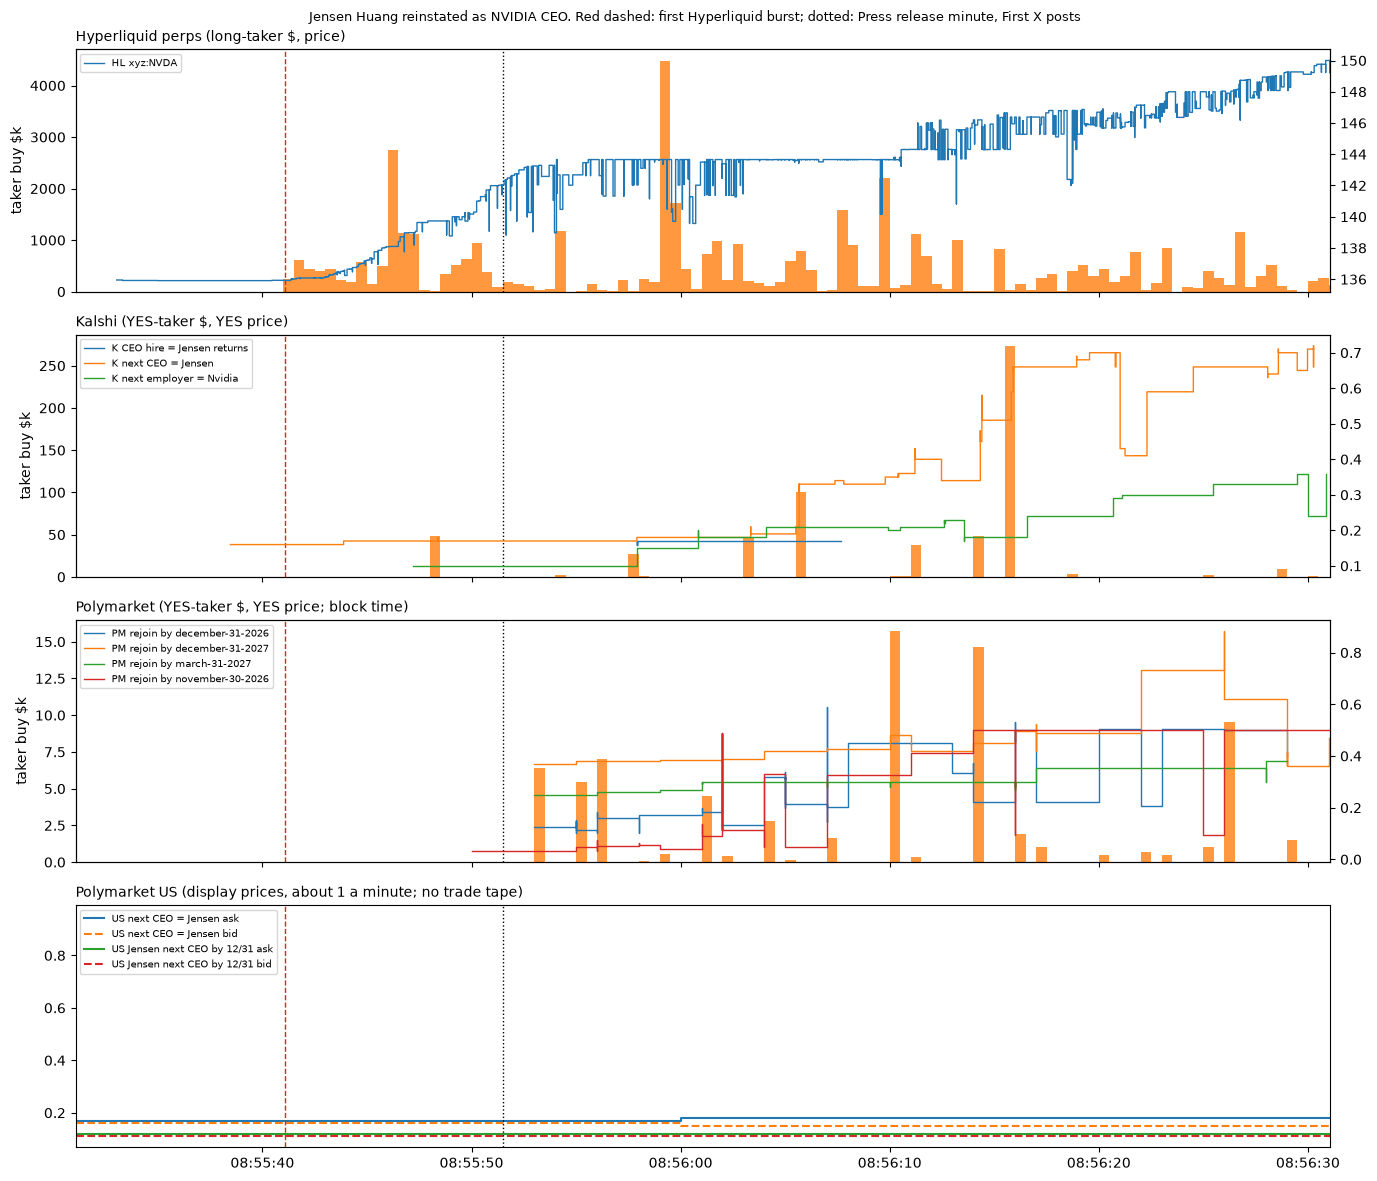

In [9]:
analysis.chart(tape, pmus, ev, hl0 - 10_000, hl0 + 50_000, 500);

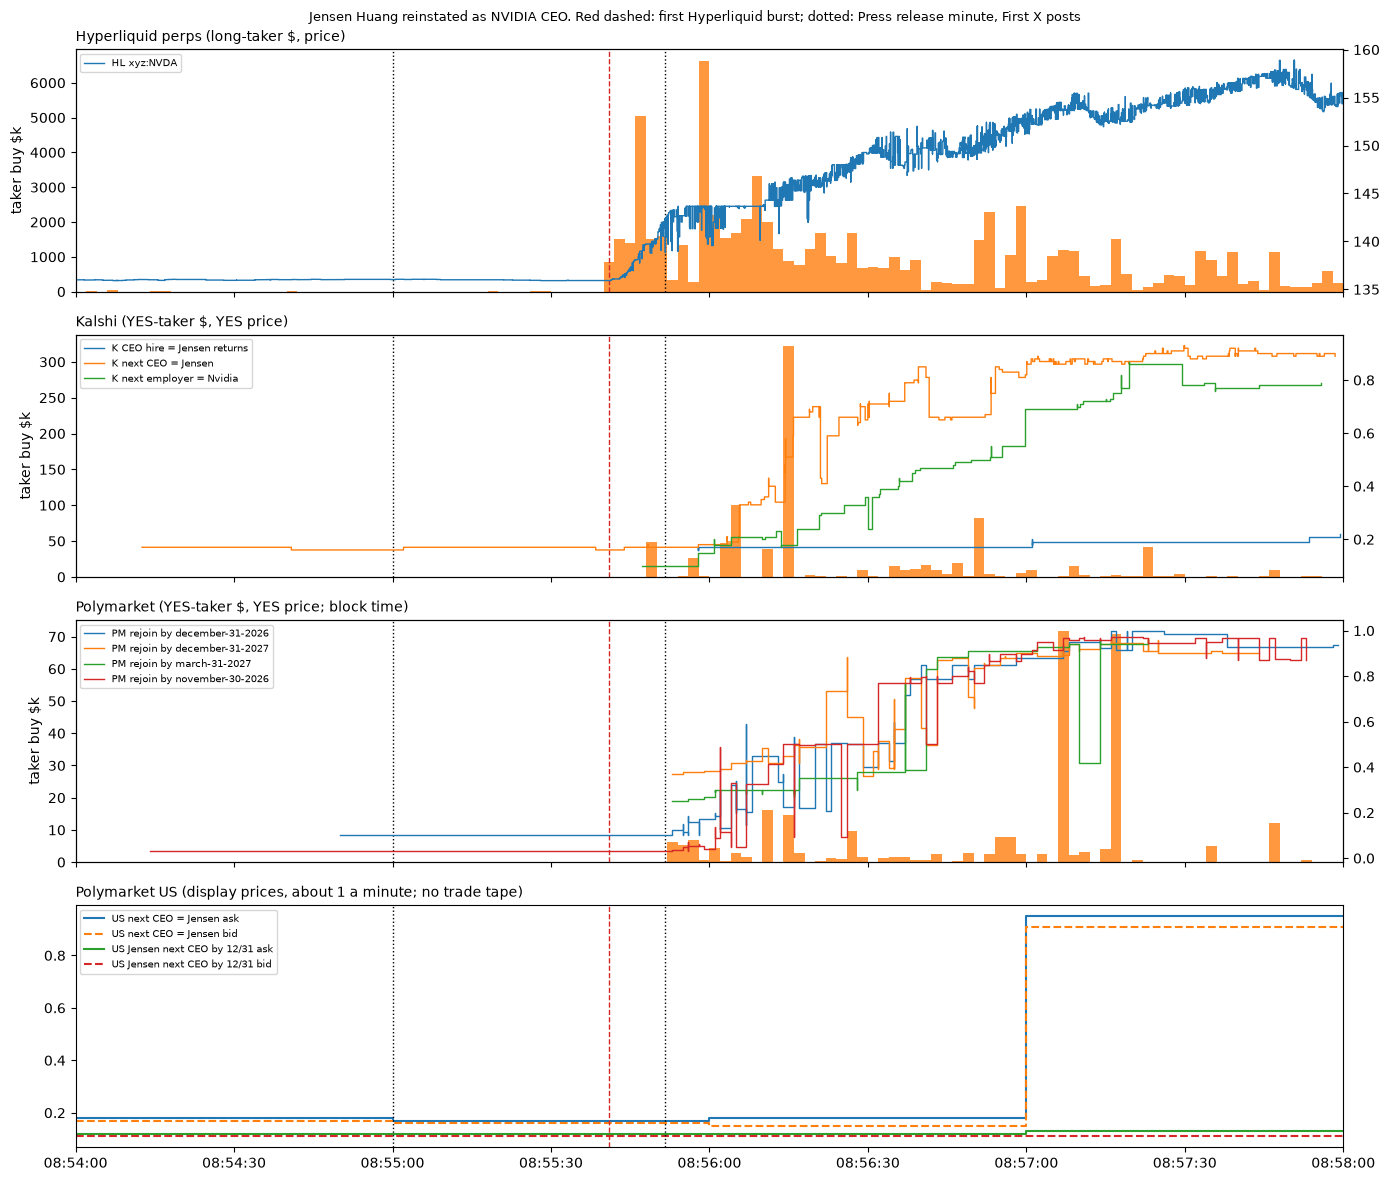

In [10]:
analysis.chart(tape, pmus, ev, ev.start_ms, ev.end_ms, 2000);

## 8. Was Hyperliquid the trigger?
One event can't separate (a) prediction-market takers watching HL NVDA and reacting to it from (b) everyone reading the same wire, with HL's bots simply fastest. Both predict HL first.

What would separate them, across a set of past news events:
1. The gap between HL's first burst and Kalshi's or Polymarket's first burst. A tight, consistent gap supports (a).
2. HL bursts with no news (false signals). If prediction markets jump on those too, takers are trading HL itself.
3. News that prediction markets priced while HL didn't move. This shows how much of the flow needs HL at all.

Each new event is a new file in `events/` plus `make all EVENT=events/<name>.toml`.